## Section 1 : Dataset Loading & Tools Setup

In [16]:
!pip install -q openpyxl gensim bnlp_toolkit

import os
import random
import numpy as np
import pandas as pd
import re
from collections import Counter

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

# Loading Dataset (using direct Excel export link)
FILE_ID = "1V4VCeVQ5rxZlsf9ycT4pgLCTyBFv5qAE"
DATASET_LINK = f"https://docs.google.com/spreadsheets/d/{FILE_ID}/export?format=xlsx"

# For reading the specific sheet
dataset = pd.read_excel(DATASET_LINK, sheet_name="bangla_news_articles", engine="openpyxl")

print("Dataset loaded successfully!")
print("Shape:", dataset.shape)
print("Number of rows :", dataset.shape[0])
print("Number of columns :", dataset.shape[1])

dataset[["publisher", "category", "title", "text"]].head(5)

Dataset loaded successfully!
Shape: (2216, 23)
Number of rows : 2216
Number of columns : 23


,publisher,category,title,text
0,BBC Bangla,crime,জেল হত্যা দিবস: ১৯৭৫ সালের ৩রা নভেম্বর কারাগার...,১৯৭৫ সালের ৩ নভেম্বর মধ্যরাতে ঢাকা কেন্দ্রীয় ...
1,BBC Bangla,other,বিবিসি বাংলার ৮৫ বছর: রেডিও থেকে স্মার্টফোনের ...,১৯৪১ সালে দ্বিতীয় বিশ্বযুদ্ধ নিয়ে যখন বিশ্বে...
2,BBC Bangla,other,কলম্বাসের ৫০০ বছর আগে আমেরিকা পৌঁছেছিল যে ভাইক...,ক্রিস্টোফার কলম্বাস ১৪৯২ সালে বিশাল সমুদ্রের ন...
3,BBC Bangla,other,মক্কায় মৃত্যুদণ্ড দেওয়া দুই বাংলাদেশির বিষয়...,সৌদি আরবের মক্কা নগরীর একটি মসজিদে 'অনৈতিক' কা...
4,BBC Bangla,politics,"রাজনৈতিক সরকারের সময়ও মব থামছে না কেন, নেপথ্য...",দেশে একের পর এক ঘটে চলেছে দলবদ্ধ বিশৃঙ্খলা বা ...


### Section 2 : Data Cleaning and Preprocessing

In [17]:
print("Missing values in each important column :")
print(dataset[["title", "description", "text", "category"]].isnull().sum())

duplicates = dataset["text"].duplicated().sum()
print("Number of duplicate articles :", duplicates)

clean_dataset = dataset.copy()

# Replacing missing Descriptions with empty text ""
title_text = clean_dataset["title"].fillna("").astype(str)
desc_text = clean_dataset["description"].fillna("").astype(str)
body_text = clean_dataset["text"].fillna("").astype(str)

clean_dataset["article_text"] = title_text + " " + desc_text + " " + body_text

category_counts = clean_dataset["category"].value_counts()
print("Original article count per category:")
print(category_counts)

# OUTPUT -->

#Missing values in each important column :
#title           0
#description    23
#text            0
#category        0
#dtype: int64
#Number of duplicate articles : 0
#Original article count per category:
#category
#other            981
#national         436
#politics         349
#crime            173
#economy           62
#international     57
#sports            46
#education         36
#entertainment     26
#health            24
#religion          11
#environment        3
#law                3
#opinion            3
#lifestyle          3
#science            2
#technology         1
#Name: count, dtype: int64

# Keepinhg those categories which have at least 20 articles
MIN_ARTICLES = 20
valid_categories = category_counts[category_counts >= MIN_ARTICLES].index

# Filtering the table to keep only valid categories
clean_dataset = clean_dataset[
    clean_dataset["category"].isin(valid_categories)
].reset_index(drop=True)

# Renaming "category" to "label"
clean_dataset = clean_dataset.rename(columns={"category": "label"})

# Printing the final summary of the dataset --->
print("Total articles remaining:", len(clean_dataset))
print("Total categories remaining:", clean_dataset["label"].nunique())
print("Final article count per category:")
print(clean_dataset["label"].value_counts())

Missing values in each important column :
title           0
description    23
text            0
category        0
dtype: int64
Number of duplicate articles : 0
Original article count per category:
category
other            981
national         436
politics         349
crime            173
economy           62
international     57
sports            46
education         36
entertainment     26
health            24
religion          11
environment        3
law                3
opinion            3
lifestyle          3
science            2
technology         1
Name: count, dtype: int64
Total articles remaining: 2190
Total categories remaining: 10
Final article count per category:
label
other            981
national         436
politics         349
crime            173
economy           62
international     57
sports            46
education         36
entertainment     26
health            24
Name: count, dtype: int64


## Section 3 : EDA

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.font_manager as fm
import urllib.request

# Downloading Bangla Font
font_url = "https://github.com/google/fonts/raw/main/ofl/notosansbengali/NotoSansBengali%5Bwdth%2Cwght%5D.ttf"
urllib.request.urlretrieve(font_url, "NotoSansBengali.ttf")
fm.fontManager.addfont("NotoSansBengali.ttf")
bangla_font = fm.FontProperties(fname = "NotoSansBengali.ttf")

# Counting articles in each category
category_counts = clean_dataset["label"].value_counts()
print("Number of articles in each category :")
print(category_counts)

# Checking the dataset if balanced or not
biggest_category_count = category_counts.iloc[0]
smallest_category_count = category_counts.iloc[-1]
print("Biggest category has :", biggest_category_count, "articles")
print("Smallest category has :", smallest_category_count, "articles")
print("The dataset is heavily imbalanced.")

# Counting the number of words and characters in each article
word_counts = []
char_counts = []

for text in clean_dataset["article_text"]:
    words = text.split()
    word_counts.append(len(words))
    char_counts.append(len(text))

clean_dataset["word_count"] = word_counts
clean_dataset["char_count"] = char_counts

print("Article Length Summary ( Words & Characters )")
print(clean_dataset[["word_count", "char_count"]].describe().round(1))

Number of articles in each category :
label
other            981
national         436
politics         349
crime            173
economy           62
international     57
sports            46
education         36
entertainment     26
health            24
Name: count, dtype: int64
Biggest category has : 981 articles
Smallest category has : 24 articles
The dataset is heavily imbalanced.
Article Length Summary ( Words & Characters )
       word_count  char_count
count      2190.0      2190.0
mean        470.8      3261.7
std         434.2      2984.8
min          62.0       421.0
25%         113.0       782.0
50%         379.0      2589.0
75%         681.0      4719.0
max        4724.0     32938.0


## Section 4 : Visual Exploration [ Graphs & Charts ]

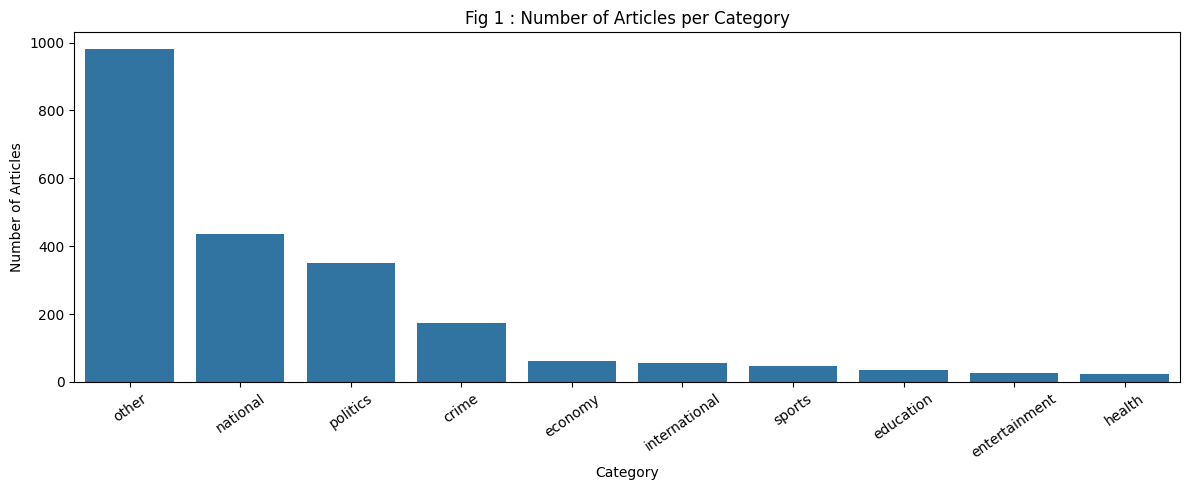

Interpretation of Figure 1 : The dataset is heavily imbalanced with 'other', 'national' and 'politics' making up most of the articles.


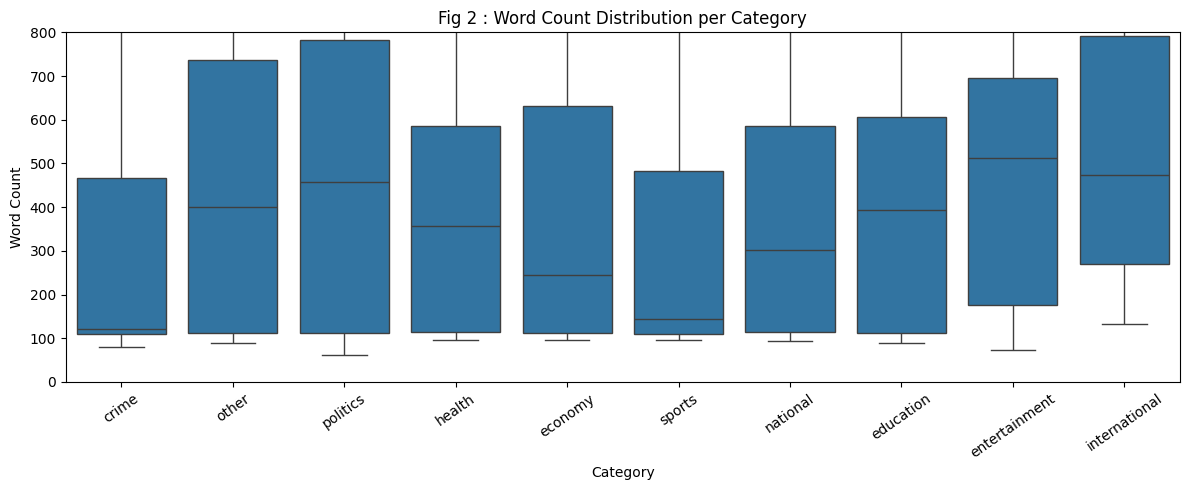

Interpretation of Figure 2 : Lengths vary widely in every class: the lower quartile is about 110 words everywhere (many short summary-style articles), while medians range from about 120 words (crime, sports) to about 500 (entertainment, international).


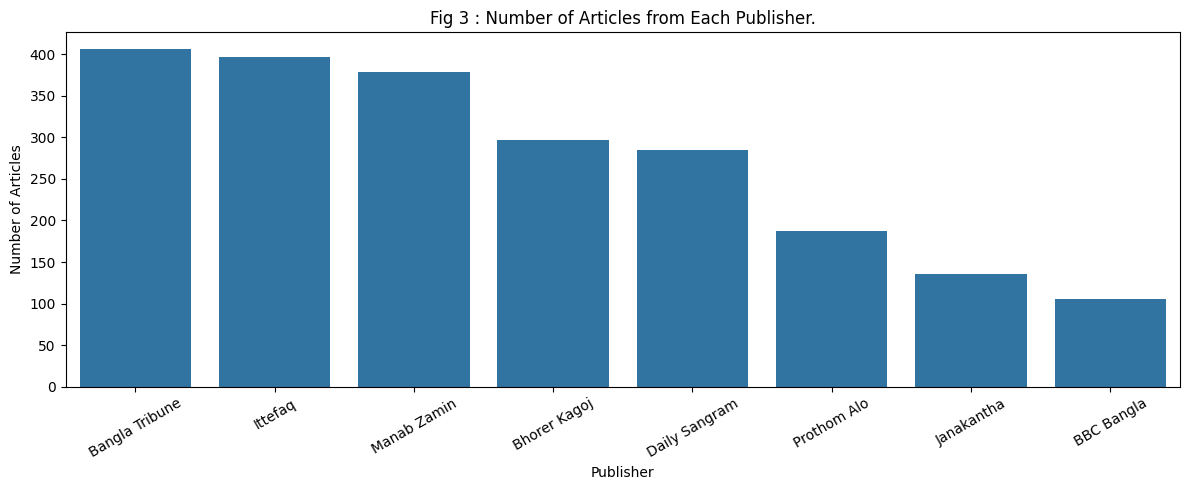

Interpretation of Figure 3 : The articles come from 8 Bangla news websites, led by Bangla Tribune, Ittefaq and Manab Zamin.


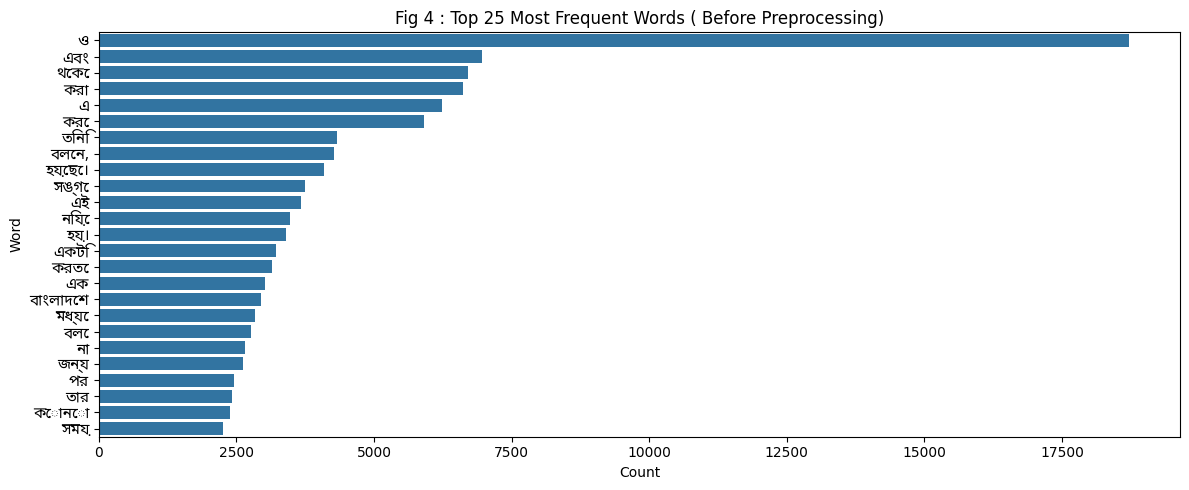

Interpretation of Figure 4 : Before cleaning, the most common words are basic Bangla filler words like 'ও', 'করে', and 'থেকে' rather than topic words.


In [19]:
# Figure 1 : Bar Chart of Categories

plt.figure(figsize=(12,5))
sns.barplot(x = category_counts.index, y = category_counts.values)
plt.title("Fig 1 : Number of Articles per Category")
plt.xlabel("Category")
plt.ylabel("Number of Articles")
plt.xticks(rotation = 35)
plt.tight_layout()
plt.show()
print("Interpretation of Figure 1 : The dataset is heavily imbalanced with 'other', 'national' and 'politics' making up most of the articles.")

# Figure 2 : Boxplot of Article Word Counts per Category

plt.figure(figsize=(12,5))
sns.boxplot(data = clean_dataset, x = "label", y = "word_count")
plt.title("Fig 2 : Word Count Distribution per Category")
plt.xlabel("Category")
plt.ylabel("Word Count")
plt.xticks(rotation = 35)
plt.ylim(0, 800) # Limiting y-axis to 800 words so the boxes are easy to read
plt.tight_layout()
plt.show()
print("Interpretation of Figure 2 : Lengths vary widely in every class: the lower quartile is about 110 words everywhere (many short summary-style articles), while medians range from about 120 words (crime, sports) to about 500 (entertainment, international).")

# Figure 3 : Bar Chart of News Publishers

publisher_counts = clean_dataset["publisher"].value_counts()

plt.figure(figsize=(12,5))
sns.barplot(x = publisher_counts.index, y = publisher_counts.values)
plt.title("Fig 3 : Number of Articles from Each Publisher.")
plt.xlabel("Publisher")
plt.ylabel("Number of Articles")
plt.xticks(rotation = 30)
#plt.ylim(0, 800) # Limiting y-axis to 800 words so the boxes are easy to read
plt.tight_layout()
plt.show()
print("Interpretation of Figure 3 : The articles come from 8 Bangla news websites, led by Bangla Tribune, Ittefaq and Manab Zamin.")

# Figure 4 : Top 30 Most Common Words

all_words = []
for text in clean_dataset["article_text"]:
    for word in text.split():
        all_words.append(word)

top_25 = Counter(all_words).most_common(25)

top_words = []
top_counts = []
for word, count in top_25:
    top_words.append(word)
    top_counts.append(count)

plt.figure(figsize=(12,5))
sns.barplot(x = top_counts, y = top_words)
plt.title("Fig 4 : Top 25 Most Frequent Words ( Before Preprocessing)")
plt.xlabel("Count")
plt.ylabel("Word")
plt.yticks(fontproperties = bangla_font, fontsize = 11)
#plt.xticks(rotation = 30)
#plt.ylim(0, 800) # Limiting y-axis to 800 words so the boxes are easy to read
plt.tight_layout()
plt.show()
print("Interpretation of Figure 4 : Before cleaning, the most common words are basic Bangla filler words like 'ও', 'করে', and 'থেকে' rather than topic words.")


In [20]:
# Top 20 Most Frequent Words per Category ( Before Preprocessing)
for category in clean_dataset["label"].unique():
    # filtering rows that belong only in label
    category_rows = clean_dataset[clean_dataset["label"] == category]
    # collecting all words from label
    words_in_category = []
    for text in category_rows["article_text"]:
        for word in text.split():
            words_in_category.append(word)

    top_20_pairs = Counter(words_in_category).most_common(20)
    top_20_words = [word for word, count in top_20_pairs]
    print(category, ":", top_20_words)

crime : ['ও', 'করা', 'এ', 'থেকে', 'করে', 'পুলিশ', 'হয়।', 'এবং', 'হয়েছে।', 'পুলিশের', 'একটি', 'গ্রেপ্তার', 'এক', 'নিয়ে', 'সঙ্গে', 'তিনি', 'সময়', 'পর', 'বলে', 'ঘটনায়']
other : ['ও', 'থেকে', 'এবং', 'করা', 'করে', 'এ', 'এই', 'হয়েছে।', 'তিনি', 'সঙ্গে', 'বলেন,', 'নিয়ে', 'একটি', 'হয়।', 'এক', 'তার', 'করতে', 'মধ্যে', 'পর', 'না']
politics : ['ও', 'এবং', 'তিনি', 'করে', 'বলেন,', 'থেকে', 'এ', 'বাংলাদেশ', 'করা', 'করতে', 'সঙ্গে', 'না', 'দাবি', 'নিয়ে', 'বলে', 'এই', 'জামায়াতে', 'জাতীয়', 'সদস্য', 'হবে।']
health : ['ও', 'এবং', 'এ', 'মৃত্যু', 'ডেঙ্গুতে', 'হাসপাতালে', 'হয়েছে।', 'জন,', 'বিভাগে', 'আক্রান্ত', 'হয়ে', 'করে', 'স্বাস্থ্য', 'থেকে', 'হাজার', 'করা', 'ডেঙ্গু', 'গত', 'ভর্তি', 'নিয়ে']
economy : ['ও', 'এ', 'থেকে', 'এবং', 'করা', 'বাংলাদেশ', 'ব্যাংক', 'হয়েছে।', 'এই', 'করে', 'কোটি', 'টাকা', 'পোশাক', 'তৈরি', 'বাংলাদেশের', 'শতাংশ', 'রপ্তানি', 'দেশের', 'এর', 'ব্যাংকের']
sports : ['ও', 'থেকে', 'এবং', 'এই', 'এক', 'তাঁর', 'করে', 'গোল', 'পর', 'জন্য', 'তবে', 'নিয়ে', 'সেই', 'বিপক্ষে', 'হয়ে', 'বাংলাদ

## Section 5 : Splitting Data & Bangla Text Preprocessing

In [21]:
from sklearn.model_selection import train_test_split

# Separate article texts and category names
texts = clean_dataset["article_text"]
labels = clean_dataset["label"]

train_texts, temp_texts, train_labels, temp_labels = train_test_split(
    texts, labels, test_size = 0.30, random_state = SEED, stratify = labels
)

val_texts, test_texts, val_labels, test_labels = train_test_split(
    temp_texts, temp_labels, test_size = 0.50, random_state = SEED, stratify = temp_labels
)

trains_texts = train_texts.reset_index(drop = True)
trains_labels = train_labels.reset_index(drop = True)

val_texts = val_texts.reset_index(drop = True)
val_labels = val_labels.reset_index(drop = True)

test_texts = test_texts.reset_index(drop = True)
test_labels = test_labels.reset_index(drop = True)

# Printing size to verify Split
print("Total articles :", len(clean_dataset))
print("Training set (70%) :", len(train_texts))
print("Validation set (15%) :", len(val_texts))
print("Test set (15%) :", len(test_texts))


Total articles : 2190
Training set (70%) : 1533
Validation set (15%) : 328
Test set (15%) : 329


In [22]:
import unicodedata
from bnlp import BasicTokenizer
#from bnlp.corpus import stopwords as bangla_stopwords_list
import re

# stopwords er library install kora jay nai
# tai manually stopwords likhte hoise

bangla_stopwords_list = [
    "এবং", "ও", "অথবা", "কিন্তু", "তবে",
    "যদি", "যে", "যা", "যার", "যাকে",
    "এই", "এটি", "এটা", "সেটি", "সেটা",
    "তিনি", "তারা", "আমি", "আমরা", "তুমি",
    "আপনি", "সে", "তাকে", "তাদের",
    "হয়", "হয়েছে", "হবে", "ছিল", "ছিলেন",
    "করে", "করেছে", "করেন", "করতে",
    "জন্য", "থেকে", "সঙ্গে", "মধ্যে",
    "উপর", "নিচে", "নিয়ে", "পর্যন্ত",
    "একটি", "এক", "অনেক", "সব", "কিছু",
    "না", "নয়", "নেই", "আর", "তো",
    "কি", "কী", "কে", "কেন", "কখন",
    "যখন", "তখন", "এখন", "এখানে", "সেখানে"
]

stop_words = set(bangla_stopwords_list)

print("Bangla stopwords loaded successfully!")
print("Total stopwords:", len(stop_words))

tokenizer = BasicTokenizer()
stop_words = set(bangla_stopwords_list)

def clean_bangla_article(raw_text, remove_stopwords = True):
  # normalize bangla unicode so broken vowel signs merge properly
  text = unicodedata.normalize("NFC", str(raw_text))

  # removing HTML tags and web urls
  text = re.sub(r"<[^>]+>", " ", text)
  text = re.sub(r"http\S+|www\.\S+", " ", text)

  # keeping only bangla letters and chars
  text = re.sub(r"[^\u0980-\u09FF\s]", " ", text)

  # removing bangla numbers and dari
  text = re.sub(r"[০-৯|]", " ", text)

  # breaking sentence into bangla words
  words = tokenizer.tokenize(text)

  # keeping only valid words
  good_words = []
  for word in words:
      if len(word) <= 1:
         continue
      if remove_stopwords == True and word in stop_words:
         continue
      good_words.append(word)

  # joining the clean words separated by spaces
  cleaned_sentence = " ".join(good_words)
  return cleaned_sentence

example_before = train_texts[0][:200]
example_after = clean_bangla_article(example_before, remove_stopwords = True)

print("Before Cleaning :", example_before)
print("\nAfter Cleaning :", example_after)



Bangla stopwords loaded successfully!
Total stopwords: 61
Before Cleaning : জেল হত্যা দিবস: ১৯৭৫ সালের ৩রা নভেম্বর কারাগারের ভেতর জাতীয় চার নেতা তাজউদ্দীন আহমেদ, সৈয়দ নজরুল ইসলাম, ক্যাপ্টেন মনসুর আলী ও এএইচএম কামরুজ্জামানকে যেভাবে খুন করা হয় ১৯৭৫ সালে তেসরা নভেম্বর ঢাকার ক

After Cleaning : জেল হত্যা দিবস সালের রা নভেম্বর কারাগারের ভেতর জাতীয় চার নেতা তাজউদ্দীন আহমেদ সৈয়দ নজরুল ইসলাম ক্যাপ্টেন মনসুর আলী এএইচএম কামরুজ্জামানকে যেভাবে খুন করা সালে তেসরা নভেম্বর ঢাকার


In [23]:
# Cleaning train, validation and test texts with stop words

print("Clearning articles with stop-words removal.")

train_clean_A = []
for text in train_texts:
    train_clean_A.append(clean_bangla_article(text, remove_stopwords = True))

val_clean_A = []
for text in val_texts:
    val_clean_A.append(clean_bangla_article(text, remove_stopwords = True))

test_clean_A = []
for text in test_texts:
    test_clean_A.append(clean_bangla_article(text, remove_stopwords = True))

print("Clearing articles without stop words removal.")

train_clean_B = []
for text in train_texts:
    train_clean_B.append(clean_bangla_article(text, remove_stopwords = False))

val_clean_B = []
for text in val_texts:
    val_clean_B.append(clean_bangla_article(text, remove_stopwords = False))

print("Cleaning done for all splits.")

print("Top 20 most frequent words after cleaning.")

temp_table = pd.DataFrame({
    "text": train_clean_A,
    "label": train_labels
})

for category in temp_table["label"].unique():
    category_rows = temp_table[temp_table["label"] == category]

    words_in_category = []
    for text in category_rows["text"]:
        for word in text.split():
            words_in_category.append(word)

    top_20_pairs = Counter(words_in_category).most_common(20)

    top_20_words = []
    for word, count in top_20_pairs:
        top_20_words.append(word)

    print(category, ":", top_20_words)

Clearning articles with stop-words removal.
Clearing articles without stop words removal.
Cleaning done for all splits.
Top 20 most frequent words after cleaning.
national : ['করা', 'বলেন', 'বাংলাদেশ', 'প্রধানমন্ত্রী', 'রহমান', 'জাতীয়', 'বলে', 'নভেম্বর', 'ঢাকা', 'এর', 'পুলিশ', 'তারেক', 'করার', 'দেওয়া', 'জানান', 'কথা', 'সরকার', 'রয়েছে', 'বিভিন্ন', 'কোনো']
politics : ['বলেন', 'বাংলাদেশ', 'করা', 'দাবি', 'রহমান', 'ঢাকা', 'সরকার', 'বলে', 'জাতীয়', 'সদস্য', 'জামায়াতে', 'কোনো', 'ভোট', 'জামায়াতের', 'করার', 'ইসলাম', 'জনগণের', 'এর', 'নির্বাচন', 'হাজার']
other : ['করা', 'বলেন', 'তার', 'এর', 'ঢাকা', 'পর', 'বলে', 'কোনো', 'বাংলাদেশ', 'পুলিশ', 'বিভিন্ন', 'সময়', 'হাজার', 'করেছেন', 'করার', 'রহমান', 'হয়ে', 'নতুন', 'টি', 'রয়েছে']
education : ['করা', 'এইচএসসি', 'জন', 'নভেম্বর', 'শিক্ষার্থীরা', 'শিক্ষার্থী', 'বিষয়ে', 'পরীক্ষায়', 'কলেজ', 'শিক্ষার্থীদের', 'পরীক্ষা', 'পরীক্ষার', 'বলেন', 'বিশ্ববিদ্যালয়ের', 'অকৃতকার্য', 'টি', 'অক্টোবর', 'শিক্ষা', 'এর', 'রহমান']
sports : ['তাঁর', 'বাংলাদেশ', 'সেই', 'হ

In [24]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

# --- Experiment A: WITH Stop-Word Removal ---
vectorizer_A = TfidfVectorizer(max_features=5000, token_pattern=r"\S+")
X_train_A = vectorizer_A.fit_transform(train_clean_A)
X_val_A = vectorizer_A.transform(val_clean_A)

classifier_A = LogisticRegression(max_iter=1000, random_state=SEED)
classifier_A.fit(X_train_A, train_labels)
predictions_A = classifier_A.predict(X_val_A)
score_A = f1_score(val_labels, predictions_A, average="macro")

# --- Experiment B: WITHOUT Stop-Word Removal ---
vectorizer_B = TfidfVectorizer(max_features=5000, token_pattern=r"\S+")
X_train_B = vectorizer_B.fit_transform(train_clean_B)
X_val_B = vectorizer_B.transform(val_clean_B)

classifier_B = LogisticRegression(max_iter=1000, random_state=SEED)
classifier_B.fit(X_train_B, train_labels)
predictions_B = classifier_B.predict(X_val_B)
score_B = f1_score(val_labels, predictions_B, average="macro")

# Print comparison table
print("--- Preprocessing Ablation Results ---")
print("Variant A (With Stop-Word Removal)    Validation Macro-F1:", round(score_A, 4))
print("Variant B (Without Stop-Word Removal) Validation Macro-F1:", round(score_B, 4))

# Automatically choose the better version for the rest of the project
if score_A >= score_B:
    print("\nWinner: Variant A (With Stop-Word Removal)")
    final_train_texts = train_clean_A
    final_val_texts = val_clean_A
    final_test_texts = test_clean_A
else:
    print("\nWinner: Variant B (Without Stop-Word Removal)")
    final_train_texts = train_clean_B
    final_val_texts = val_clean_B
    final_test_texts = []
    for text in test_texts:
        final_test_texts.append(clean_bangla_article(text, remove_stopwords=False))

--- Preprocessing Ablation Results ---
Variant A (With Stop-Word Removal)    Validation Macro-F1: 0.1958
Variant B (Without Stop-Word Removal) Validation Macro-F1: 0.1934

Winner: Variant A (With Stop-Word Removal)


## Section 6 : Text Representations ( Bag of Words, TF-IDF, Word2Vec )

In [25]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from gensim.models import Word2Vec

# Our cleaned articles are already separated by spaces.
# So we tell the vectorizers to split only on spaces.
# (The default splitter breaks Bangla words at the vowel signs, so we do not use it.)
TOKEN_PATTERN = r"\S+"
MAX_WORDS = 20000

# =========================================================
# 1. Bag of Words (BoW) : word counts
# =========================================================
bow_vectorizer = CountVectorizer(max_features = MAX_WORDS, token_pattern = TOKEN_PATTERN)

# Learn the vocabulary from the training set only
X_train_bow = bow_vectorizer.fit_transform(final_train_texts)
X_val_bow = bow_vectorizer.transform(final_val_texts)
X_test_bow = bow_vectorizer.transform(final_test_texts)

print("BoW matrix shape (train) :", X_train_bow.shape)

# =========================================================
# 2. TF-IDF : unigram vs unigram + bigram
# =========================================================
# Setting 1 : single words only
tfidf_unigram = TfidfVectorizer(max_features = MAX_WORDS, token_pattern = TOKEN_PATTERN, ngram_range = (1, 1))
X_train_tfidf_uni = tfidf_unigram.fit_transform(final_train_texts)
X_val_tfidf_uni = tfidf_unigram.transform(final_val_texts)

# Setting 2 : single words + pairs of words
tfidf_bigram = TfidfVectorizer(max_features = MAX_WORDS, token_pattern = TOKEN_PATTERN, ngram_range = (1, 2))
X_train_tfidf_bi = tfidf_bigram.fit_transform(final_train_texts)
X_val_tfidf_bi = tfidf_bigram.transform(final_val_texts)

# Compare both settings on the validation set (with Logistic Regression)
check_uni = LogisticRegression(max_iter = 1000, class_weight = "balanced", random_state = SEED)
check_uni.fit(X_train_tfidf_uni, train_labels)
uni_f1 = f1_score(val_labels, check_uni.predict(X_val_tfidf_uni), average = "macro")

check_bi = LogisticRegression(max_iter = 1000, class_weight = "balanced", random_state = SEED)
check_bi.fit(X_train_tfidf_bi, train_labels)
bi_f1 = f1_score(val_labels, check_bi.predict(X_val_tfidf_bi), average = "macro")

print("TF-IDF Unigram (1,1) Validation Macro-F1         :", round(uni_f1, 4))
print("TF-IDF Unigram + Bigram (1,2) Validation Macro-F1:", round(bi_f1, 4))

# Keep the setting that has the better validation score
if bi_f1 > uni_f1:
    print("Selected TF-IDF setting : Unigram + Bigram (1, 2)")
    best_tfidf_vectorizer = tfidf_bigram
    X_train_tfidf = X_train_tfidf_bi
    X_val_tfidf = X_val_tfidf_bi
else:
    print("Selected TF-IDF setting : Unigram (1, 1)")
    best_tfidf_vectorizer = tfidf_unigram
    X_train_tfidf = X_train_tfidf_uni
    X_val_tfidf = X_val_tfidf_uni

X_test_tfidf = best_tfidf_vectorizer.transform(final_test_texts)

# =========================================================
# 3. Word2Vec : average word vectors (trained on training articles only)
# =========================================================
# Splitting every training article into a list of words
train_word_lists = []
for text in final_train_texts:
    train_word_lists.append(text.split())

EMBEDDING_SIZE = 100
w2v_model = Word2Vec(
    sentences = train_word_lists,
    vector_size = EMBEDDING_SIZE,
    window = 5,
    min_count = 2,
    epochs = 20,
    workers = 1,        # workers = 1 keeps the result the same every run
    seed = SEED
)

# Turning every article into ONE vector = average of its word vectors
def get_average_word2vec(article_list):
    all_vectors = []
    for text in article_list:
        word_vectors = []
        for word in text.split():
            if word in w2v_model.wv:
                word_vectors.append(w2v_model.wv[word])

        if len(word_vectors) > 0:
            article_vector = np.mean(word_vectors, axis = 0)
        else:
            article_vector = np.zeros(EMBEDDING_SIZE)   # no known word in this article

        all_vectors.append(article_vector)
    return np.array(all_vectors)

X_train_w2v = get_average_word2vec(final_train_texts)
X_val_w2v = get_average_word2vec(final_val_texts)
X_test_w2v = get_average_word2vec(final_test_texts)

print("Word2Vec matrix shape (train) :", X_train_w2v.shape)

BoW matrix shape (train) : (1533, 20000)
TF-IDF Unigram (1,1) Validation Macro-F1         : 0.3845
TF-IDF Unigram + Bigram (1,2) Validation Macro-F1: 0.3777
Selected TF-IDF setting : Unigram (1, 1)
Word2Vec matrix shape (train) : (1533, 100)


In [26]:
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB

# Values we try for each model (the best one is chosen on the VALIDATION set)
alpha_values = [0.01, 0.1, 0.5, 1.0, 2.0]    # for Naive Bayes
C_values = [0.1, 1.0, 10.0, 100.0]           # for Logistic Regression

# Lists / dictionaries to keep the results
validation_records = []
best_models = {}

def save_result(name, model, X_test_data, hyper_text, val_score):
    # Keeping the model together with its test matrix (used later in Section 7)
    best_models[name] = (model, X_test_data)
    validation_records.append({
        "Model Configuration": name,
        "Best Hyperparameter": hyper_text,
        "Validation Macro-F1": round(val_score, 4)
    })

def tune_naive_bayes(X_train_data, X_val_data):
    # Trying every alpha and keeping the best one
    best_score = -1
    best_model = None
    best_alpha = None
    for alpha in alpha_values:
        model = MultinomialNB(alpha = alpha)
        model.fit(X_train_data, train_labels)
        score = f1_score(val_labels, model.predict(X_val_data), average = "macro")
        if score > best_score:
            best_score = score
            best_model = model
            best_alpha = alpha
    return best_model, "alpha=" + str(best_alpha), best_score

def tune_logistic_regression(X_train_data, X_val_data):
    # Trying every C value and keeping the best one
    best_score = -1
    best_model = None
    best_C = None
    for c_val in C_values:
        model = LogisticRegression(C = c_val, max_iter = 1000, class_weight = "balanced", random_state = SEED)
        model.fit(X_train_data, train_labels)
        score = f1_score(val_labels, model.predict(X_val_data), average = "macro")
        if score > best_score:
            best_score = score
            best_model = model
            best_C = c_val
    return best_model, "C=" + str(best_C), best_score

# =========================================================
# Model 1 : Majority-class baseline (no tuning needed)
# =========================================================
baseline_model = DummyClassifier(strategy = "most_frequent")
baseline_model.fit(X_train_bow, train_labels)
baseline_score = f1_score(val_labels, baseline_model.predict(X_val_bow), average = "macro")
save_result("Majority Baseline", baseline_model, X_test_bow, "None", baseline_score)

# =========================================================
# Model 2 : Multinomial Naive Bayes + BoW
# =========================================================
model, hyper, score = tune_naive_bayes(X_train_bow, X_val_bow)
save_result("BoW + Multinomial NB", model, X_test_bow, hyper, score)

# =========================================================
# Model 3 : Multinomial Naive Bayes + TF-IDF
# =========================================================
model, hyper, score = tune_naive_bayes(X_train_tfidf, X_val_tfidf)
save_result("TF-IDF + Multinomial NB", model, X_test_tfidf, hyper, score)

# =========================================================
# Model 4 : Logistic Regression + BoW
# =========================================================
model, hyper, score = tune_logistic_regression(X_train_bow, X_val_bow)
save_result("BoW + Logistic Regression", model, X_test_bow, hyper, score)

# =========================================================
# Model 5 : Logistic Regression + TF-IDF
# =========================================================
model, hyper, score = tune_logistic_regression(X_train_tfidf, X_val_tfidf)
save_result("TF-IDF + Logistic Regression", model, X_test_tfidf, hyper, score)

# =========================================================
# Model 6 : Logistic Regression + Word2Vec
# (Naive Bayes is not used here because Word2Vec numbers can be negative)
# =========================================================
model, hyper, score = tune_logistic_regression(X_train_w2v, X_val_w2v)
save_result("Word2Vec + Logistic Regression", model, X_test_w2v, hyper, score)

# =========================================================
# Validation results table and the best model
# =========================================================
validation_table = pd.DataFrame(validation_records)
print("--- Validation Set Results ---")
print(validation_table.to_string(index = False))

# The best model = highest validation Macro-F1 (the baseline is not counted)
trained_models_table = validation_table[validation_table["Model Configuration"] != "Majority Baseline"]
best_row = trained_models_table.loc[trained_models_table["Validation Macro-F1"].idxmax()]
selected_best_model_name = best_row["Model Configuration"]

print("\nBest model (selected on validation Macro-F1) :", selected_best_model_name, "-", best_row["Validation Macro-F1"])

--- Validation Set Results ---
           Model Configuration Best Hyperparameter  Validation Macro-F1
             Majority Baseline                None               0.0619
          BoW + Multinomial NB           alpha=2.0               0.3799
       TF-IDF + Multinomial NB          alpha=0.01               0.3601
     BoW + Logistic Regression               C=0.1               0.4115
  TF-IDF + Logistic Regression               C=1.0               0.3845
Word2Vec + Logistic Regression               C=1.0               0.3587

Best model (selected on validation Macro-F1) : BoW + Logistic Regression - 0.4115


## Section 7 : Final Test Evaluation & Error Analysis

--- Final Test Set Results ---
   Representation + Classifier  Accuracy  Macro-Precision  Macro-Recall  Macro-F1
             Majority Baseline    0.4468           0.0447        0.1000    0.0618
          BoW + Multinomial NB    0.5927           0.4504        0.3760    0.3782
       TF-IDF + Multinomial NB    0.5532           0.4893        0.4400    0.4364
     BoW + Logistic Regression    0.6231           0.6549        0.5096    0.5511
  TF-IDF + Logistic Regression    0.5350           0.5046        0.6168    0.5015
Word2Vec + Logistic Regression    0.3982           0.3296        0.5763    0.3595

Model selected on validation Macro-F1 : BoW + Logistic Regression


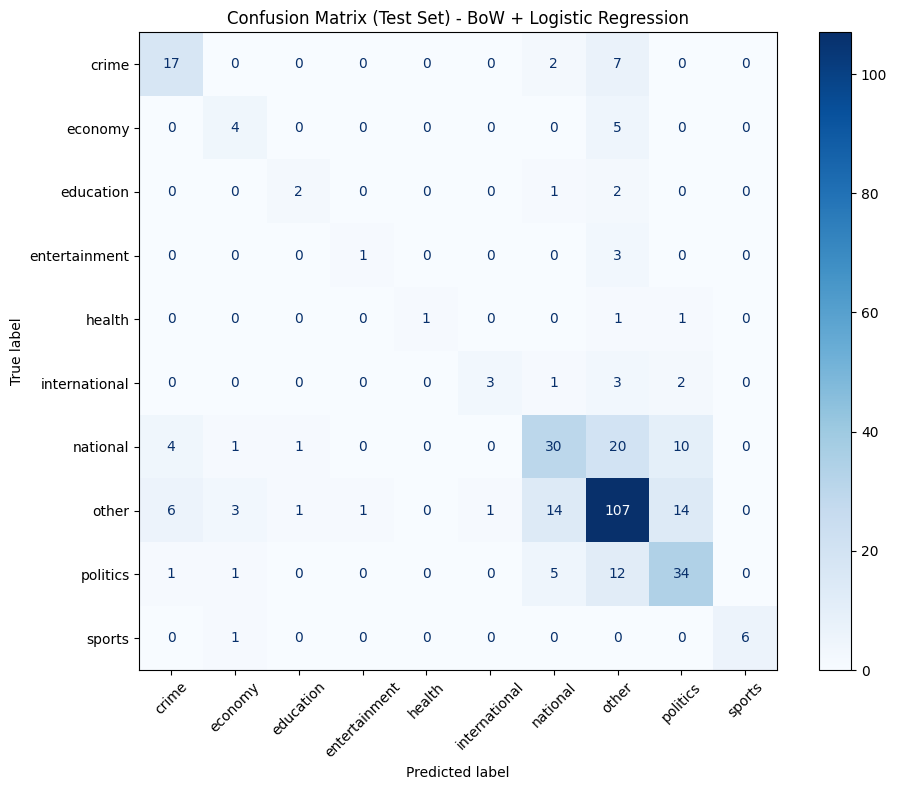

In [27]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

# =========================================================
# Step 1 : Test every model ONE time on the test set
# =========================================================
test_results = []

for model_name in best_models:
    model, X_test_data = best_models[model_name]
    test_predictions = model.predict(X_test_data)

    # zero_division = 0 avoids warnings when a class gets no prediction
    accuracy = accuracy_score(test_labels, test_predictions)
    macro_precision = precision_score(test_labels, test_predictions, average = "macro", zero_division = 0)
    macro_recall = recall_score(test_labels, test_predictions, average = "macro", zero_division = 0)
    macro_f1 = f1_score(test_labels, test_predictions, average = "macro", zero_division = 0)

    test_results.append({
        "Representation + Classifier": model_name,
        "Accuracy": round(accuracy, 4),
        "Macro-Precision": round(macro_precision, 4),
        "Macro-Recall": round(macro_recall, 4),
        "Macro-F1": round(macro_f1, 4)
    })

final_comparison_table = pd.DataFrame(test_results)
print("--- Final Test Set Results ---")
print(final_comparison_table.to_string(index = False))
print("\nModel selected on validation Macro-F1 :", selected_best_model_name)

# =========================================================
# Step 2 : Confusion matrix of the selected model
# =========================================================
winning_model, winning_X_test = best_models[selected_best_model_name]
winning_test_preds = winning_model.predict(winning_X_test)

class_names = sorted(test_labels.unique())
cm = confusion_matrix(test_labels, winning_test_preds, labels = class_names)

fig, ax = plt.subplots(figsize = (10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix = cm, display_labels = class_names)
disp.plot(ax = ax, cmap = "Blues", xticks_rotation = 45, values_format = "d")
plt.title("Confusion Matrix (Test Set) - " + selected_best_model_name)
plt.tight_layout()
plt.show()

In [28]:
# We use the BoW + Naive Bayes model, because BoW features are single whole words
nb_model = best_models["BoW + Multinomial NB"][0]
feature_names = bow_vectorizer.get_feature_names_out()
log_probs = nb_model.feature_log_prob_      # one row for each class, one column for each word

print("--- Top 10 Most Informative Words per Class (Naive Bayes log-probability ratio) ---")

for i in range(len(nb_model.classes_)):
    class_name = nb_model.classes_[i]

    # How likely is each word in this class?
    this_class_log_prob = log_probs[i]

    # How likely is each word in the other classes? (average)
    other_classes_log_prob = np.delete(log_probs, i, axis = 0).mean(axis = 0)

    # Big difference = the word belongs strongly to this class
    ratio = this_class_log_prob - other_classes_log_prob

    # Taking the 10 words with the biggest ratio
    top_10_indices = np.argsort(ratio)[-10:][::-1]

    top_words = []
    for index in top_10_indices:
        top_words.append(feature_names[index])

    print(class_name, ":", ", ".join(top_words))

--- Top 10 Most Informative Words per Class (Naive Bayes log-probability ratio) ---
crime : থানায়, গ্রেপ্তার, জিডি, থানার, পুলিশ, মামলায়, গুলি, আদালত, পুলিশের, মামলাটি
economy : রপ্তানি, ব্যাংক, ডলার, ডলারে, শতাংশ, অর্থবছরের, রপ্তানিতে, বিশ্বব্যাংকের, প্রবৃদ্ধি, ডলারের
education : এইচএসসি, অকৃতকার্য, বাণিজ্যমেলার, পরীক্ষায়, শিক্ষার্থীরা, সামসুল, কদমতলী, পরীক্ষার, পরীক্ষা, স্কুল
entertainment : ঋত্বিক, অভিনয়, শিডিউল, শুটিং, ছবির, সিনেমার, চলচ্চিত্র, কনসার্ট, ঋত্বিকের, অভিনয়ের
health : ডেঙ্গুতে, বিভাগে, আক্রান্ত, ডেঙ্গু, মৃত্যু, স্বাস্থ্য, ভর্তি, জনের, হামের, হাম
international : নেতানিয়াহুর, ট্রাম্প, ইরানের, সিনেটের, অঙ্গরাজ্যের, আইজেনকটের, যুদ্ধ, হরমুজ, ইসরায়েলের, ক্রিপ্টোকারেন্সি
national : জাপানের, প্রধানমন্ত্রী, তারেক, জাপান, আইজিপির, প্রতিমন্ত্রী, বিমান, আইজিপি, নিবন্ধন, ত্রুটি
other : রান, বিএনপি, তার, জেলা, সম্পাদিত, অভিনেত্রী, কাওরান, জেনিথ, মাহবুবা, প্রিন্টার্স
politics : ঠাকুরগাঁও, ভোট, জামায়াতের, আমীর, উপনির্বাচনে, শফিকুর, বিরোধীদলীয়, জনগণের, জামায়াতে, লংমার্চের
spor

In [29]:
# Collecting all test articles that the selected model got wrong
misclassified_rows = []

for i in range(len(test_labels)):
    true_category = test_labels[i]
    predicted_category = winning_test_preds[i]

    if true_category != predicted_category:
        misclassified_rows.append({
            "True_Category": true_category,
            "Predicted_Category": predicted_category,
            "Words": len(test_texts[i].split()),
            "Article_Start": test_texts[i][:150].replace("\n", " ") + "..."
        })

misclassified_df = pd.DataFrame(misclassified_rows)
print("Total misclassified test articles :", len(misclassified_df), "out of", len(test_labels))

# Taking 25 random mistakes (same 25 every run because of the seed)
sample_errors = misclassified_df.sample(25, random_state = SEED).reset_index(drop = True)

print("\n--- 25 Misclassified Test Examples ---")
for i in range(len(sample_errors)):
    row = sample_errors.iloc[i]
    print("[" + str(i + 1) + "] True :", row["True_Category"], "| Predicted :", row["Predicted_Category"], "| Words :", row["Words"])
    print("    ", row["Article_Start"], "\n")

# =========================================================
# Manual error types (we read the 25 examples above and write the type of each one)
# =========================================================
# Example types : "Label noise", "Overlapping classes", "Very short article", "Long article", "Other"
my_error_types = {
    1: "Overlapping classes",        2: "Overlapping classes",        3: "Catch-all other label",
    4: "Overlapping classes",        5: "Catch-all other label",      6: "Predicted other by default",
    7: "Rare class",                 8: "Overlapping classes",        9: "Overlapping classes",
    10: "Likely label noise",        11: "Catch-all other label",     12: "Predicted other by default",
    13: "Likely label noise",        14: "Predicted other by default", 15: "Overlapping classes",
    16: "Rare class",                17: "Rare class",                18: "Likely label noise",
    19: "Overlapping classes",       20: "Catch-all other label",     21: "Predicted other by default",
    22: "Predicted other by default", 23: "Rare class",               24: "Predicted other by default",
    25: "Likely label noise",
}

print("Examples categorised :", len(my_error_types), "out of 25")
if len(my_error_types) > 0:
    sample_errors["Error_Type"] = ""
    for number in my_error_types:
        sample_errors.loc[number - 1, "Error_Type"] = my_error_types[number]
    print(sample_errors["Error_Type"].value_counts())

Total misclassified test articles : 124 out of 329

--- 25 Misclassified Test Examples ---
[1] True : national | Predicted : economy | Words : 359
     ডিসেম্বরের মধ্যে ন্যূনতম মজুরি নির্ধারণ: মজুরি বোর্ড চলতি বছরের ডিসেম্বরের মধ্যে তৈরি পোশাকশ্রমিকদের নতুন ন্যূনতম মজুরি কাঠামো নির্ধারণ করা হবে। নতুন ... 

[2] True : national | Predicted : politics | Words : 104
     আমজনতার তারেক রহমান ছাত্রদলের সদস্য ছিলেন: জানালেন ছাত্রদল নেতা শুভ আমজনতা দলের সদস্যসচিব তারেক রহমান কুমিল্লা বিশ্ববিদ্যালয়ে (কুবি) অধ্যয়নকালে ছাত্... 

[3] True : other | Predicted : crime | Words : 1015
     বারুইপুর, গাইঘাটা, সামশেরগঞ্জ: পশ্চিমবঙ্গের কথিত এনকাউন্টারগুলো যে প্রশ্ন উসকে দিচ্ছে গাইঘাটায় ১৭ বছর বয়সী এক শিক্ষার্থীকে ধর্ষণের অভিযোগে তারই এক আ... 

[4] True : national | Predicted : politics | Words : 152
     কোস্টগার্ডের পাঁচ জাহাজের নাম পরিবর্তন,বাদ ‘জয় বাংলা’ ও জাতীয় চার নেতা বাংলাদেশ কোস্ট গার্ডের পাঁচটি জাহাজের নাম পরিবর্তন করেছে সরকার। এর মধ্যে একটি... 

[5] True : other | Predicted : crime | Word